# 03 -- Free-COO / BFGS-budget sweeps on larger systems

**Status: pilot stage.** One representative recovery point per system, plus a small
2-point BFGS-budget curve (the established, independently-rediagonalized budget-vs-gain
relationship -- **not** internal per-iteration BFGS tracing: the standalone
`orbital_bfgs_optimize` trace depends on a native `davidson_solve` subspace-stall
pathology that is unresolved and out of scope for this release; see
`docs/reports/trimci_davidson_stall_hardening_item_2026-09-25.md`. Nothing here uses
that trace).

Systems: AlFe2 (11e,20o), Fe2S2 (30e,20o, **reference-free stress case** -- no published
ground truth exists for this FCIDUMP), FeS dimer 3- (11e,20o, published DMRG reference from
the LASSIS paper). Workflow: `frasci.parent.solve()` -> `frasci.recovery.solve()`
(generalized / union / free-COO).


In [1]:
import sys
from pathlib import Path

RELEASE_ROOT = Path.cwd().parent
if not (RELEASE_ROOT / "frasci" / "__init__.py").exists():
    RELEASE_ROOT = Path.cwd()
assert (RELEASE_ROOT / "frasci" / "__init__.py").exists(), (
    f"release root not found relative to {Path.cwd()}")

assert "frasci" not in sys.modules, (
    "frasci was already imported before the release-first bootstrap ran")

sys.path.insert(0, str(RELEASE_ROOT))

import frasci
frasci_path = Path(frasci.__file__).resolve()
assert frasci_path.is_relative_to(RELEASE_ROOT.resolve()), (
    f"Using frasci from {frasci_path}, NOT from the release root {RELEASE_ROOT} -- "
    "the dev-tree package shadowed the release one")
print(f"Using FRASCI from: {frasci_path}")
print(f"frasci.__version__: {getattr(frasci, '__version__', 'unknown')}")

import frasci.parent as parent_pkg
import frasci.recovery as recovery_pkg
print("parent pkg importable:", bool(parent_pkg))
print("recovery pkg importable:", bool(recovery_pkg))


Using FRASCI from: /Users/abhimuvva/Documents/Masters_Projs/Proj_Flow/LASSCF_TRIMCI_COO/release/FRASCI/frasci/__init__.py
frasci.__version__: 0.2.0.dev0
parent pkg importable: True
recovery pkg importable: True


In [2]:
import time, json, shutil
from pathlib import Path

from frasci import FCIDUMPInput
from frasci.parent import ParentConfig, solve as solve_parent
from frasci.recovery import RecoveryConfig, solve as solve_recovery

RUN_ROOT = Path("/tmp/frasci_nb03_runs")
shutil.rmtree(RUN_ROOT, ignore_errors=True)
RUN_ROOT.mkdir(parents=True)

RESULTS_DIR = Path("data/results/03_free_coo_bfgs_sweeps")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SYSTEMS = {
    "alfe2_11o20e": dict(
        physical_space="(11e,20o)",
        orbital_lists=[[0,1,2,3,4,5,6,7,8,9],[10,11,12,13,14,15,16,17,18,19]],
        nelec_per_frag=[(1,5),(5,0)], spin_sub=[5,6], reference_ha=None),
    "fes_dimer_3minus": dict(
        physical_space="(11e,20o)",
        orbital_lists=[[0,1,2,3,4,5,6,7,8,9],[10,11,12,13,14,15,16,17,18,19]],
        nelec_per_frag=[(5,1),(0,5)], spin_sub=[5,6],
        reference_ha=-5068.75665440243),  # LASSIS paper, DMRG M=1000, S=1/2 ground state
    "fe2s2": dict(
        physical_space="(30e,20o)",
        orbital_lists=[[2,3,4,5,6,13,14,15,16,17],[0,1,7,8,9,10,11,12,18,19]],
        nelec_per_frag=[(10,10),(5,5)], spin_sub=[1,1], reference_ha=None),
}

PCFG_DEFAULT = dict(threshold=1e-5, max_cycle_macro=20, orbopt=True, orbopt_cycles=5,
                     phase0_dets=100, phase1_dets=1000, discovery_num_runs=16,
                     refine_num_runs=1, rng_seed=0, n_cpu_workers=0)
RCFG_DEFAULT = dict(recovery_target=2000, n_ct_max=2, las_top_k=1000,
                     free_coo_orbital_opt_max_iter=50)


## Representative point, AlFe2(11e,20o) and FeS-dimer-3- (published-reference systems)

Mid-scale, real config: `phase1_dets=1000`, `recovery_target=2000`, `las_top_k=1000`,
BFGS budget 50 -- not the full sweep grid's largest points.


In [3]:
def run_recovery_point(name, spec, parent_dir, rcfg_kwargs):
    fcidump_path = Path("data") / name / "FCIDUMP"
    bundle = FCIDUMPInput.from_file(str(fcidump_path))
    rcfg = RecoveryConfig(**rcfg_kwargs)
    t0 = time.time()
    result = solve_recovery(parent_dir, bundle, rcfg)
    wall = time.time() - t0
    return {
        "config": rcfg_kwargs,
        "energies_ha": {"h00": result.h00, "generalized": result.energy,
                          "union": result.union_energy, "free_coo": result.free_coo_energy},
        "determinants": {"requested": rcfg_kwargs["recovery_target"], "achieved": result.n_dets,
                            "target_met": result.diagnostics.get("target_met")},
        "gates": result.gates, "wall_s": round(wall, 3),
        "free_coo_gain_mha": result.free_coo_gain_mha,
    }


results = {}
parents = {}
for name in ("alfe2_11o20e", "fes_dimer_3minus"):
    spec = SYSTEMS[name]
    fcidump_path = Path("data") / name / "FCIDUMP"
    pcfg = ParentConfig(**PCFG_DEFAULT)
    save_dir = RUN_ROOT / f"{name}_parent"
    t0 = time.time()
    parent = solve_parent(str(fcidump_path), spec["orbital_lists"], spec["nelec_per_frag"],
                           spec["spin_sub"], pcfg, save_dets_to=save_dir)
    t_parent = time.time() - t0
    parents[name] = save_dir
    print(f"\n=== {name} ({spec['physical_space']}) ===")
    print(f"parent: converged={parent.converged} e_tot={parent.e_tot:.6f} wall={t_parent:.1f}s")

    point = run_recovery_point(name, spec, save_dir, RCFG_DEFAULT)
    print("recovery point:", point)
    results[name] = {"physical_space": spec["physical_space"], "reference_ha": spec["reference_ha"],
                       "parent": {"converged": parent.converged, "e_tot": parent.e_tot,
                                    "wall_s": round(t_parent, 3)},
                       "recovery_point": point}


Parsing data/alfe2_11o20e/FCIDUMP



******** LASSCF flags ********


CAS (6e+5e, 20o), ncore = 0, nvir = 0


Divided into 2 LAS spaces


LAS 0 : (1e+5e, 10o)


LAS 1 : (5e+0e, 10o)


... (428 outputs left out)

  Davidson converged in 1 iterations  E = -28.9080845784  |r| = 8.72e-04
  Davidson converged in 1 iterations  E = -28.9080848329  |r| = 5.55e-04
  Davidson converged in 1 iterations  E = -28.9080848832  |r| = 4.57e-04
  Davidson converged in 1 iterations  E = -28.9080846049  |r| = 7.87e-04
  Davidson converged in 1 iterations  E = -28.9080848381  |r| = 5.06e-04
  Davidson converged in 1 iterations  E = -28.9080848841  |r| = 4.39e-04
  Davidson converged in 1 iterations  E = -28.9080846290  |r| = 8.36e-04
  Davidson converged in 1 iterations  E = -28.9080848428  |r| = 5.47e-04
  Davidson converged in 1 iterations  E = -28.9080848850  |r| = 4.57e-04


  Davidson converged in 1 iterations  E = -28.9080846511  |r| = 7.49e-04
  Davidson converged in 1 iterations  E = -28.9080848472  |r| = 4.97e-04
  Davidson converged in 1 iterations  E = -28.9080848859  |r| = 4.40e-04
  Davidson converged in 1 iterations  E = -28.9080846713  |r| = 8.03e-04
  Davidson converged in 1 iterations  E = -28.9080848512  |r| = 5.38e-04
  Davidson converged in 1 iterations  E = -28.9080848867  |r| = 4.57e-04
  Davidson converged in 1 iterations  E = -28.9080846897  |r| = 7.15e-04
  Davidson converged in 1 iterations  E = -28.9080848549  |r| = 4.89e-04
  Davidson converged in 1 iterations  E = -28.9080848875  |r| = 4.41e-04


  Davidson converged in 1 iterations  E = -28.9080847067  |r| = 7.70e-04
  Davidson converged in 1 iterations  E = -28.9080848583  |r| = 5.30e-04
  Davidson converged in 1 iterations  E = -28.9080848882  |r| = 4.58e-04
  Davidson converged in 1 iterations  E = -28.9080847221  |r| = 6.83e-04
  Davidson converged in 1 iterations  E = -28.9080848615  |r| = 4.83e-04
  Davidson converged in 1 iterations  E = -28.9080848889  |r| = 4.42e-04
  Davidson converged in 1 iterations  E = -28.9080847364  |r| = 7.40e-04
  Davidson converged in 1 iterations  E = -28.9080848644  |r| = 5.23e-04
  Davidson converged in 1 iterations  E = -28.9080848896  |r| = 4.58e-04
  [OrbOpt Profile] 50 iters: 2RDM=1.97s (54.47%), Fock+grad=0.14s (3.92%), rotate=0.06s (1.71%), diag=1.44s (39.90%)


recovery point: {'config': {'recovery_target': 2000, 'n_ct_max': 2, 'las_top_k': 1000, 'free_coo_orbital_opt_max_iter': 50}, 'energies_ha': {'h00': -5068.7478253602285, 'generalized': -5068.748512044854, 'union': -5068.748515030234, 'free_coo': -5068.748656216852}, 'determinants': {'requested': 2000, 'achieved': 2000, 'target_met': True}, 'gates': {'E_hybrid_le_H00': True, 'E_hybrid_le_E_C': True, 'S_positive_semidefinite': True, 'c_dagger_S_c_eq_1': True, 'no_pt2_mixed_with_variational': True, 'generalized_residual_converged': True}, 'wall_s': 138.376, 'free_coo_gain_mha': 0.16823904297780246}


## Small BFGS-budget curve (2 points: 20 and 100) -- reusing the same converged parent

This is the *established budget curve* the sweep grid calls "F-gain-bfgs": free-COO gain
as a function of `free_coo_orbital_opt_max_iter`, with the energy at every budget
independently rediagonalized (never taken from TrimCI's own paired output, per the
release's own README section 5). Only 2 of the full grid's 4 budgets (20, 50, 100, 150)
are run here -- a pilot-scale demonstration that the curve mechanism works and a real
timing sample, not the full sweep.


In [4]:
budget_curve = {}
for name in ("alfe2_11o20e", "fes_dimer_3minus"):
    spec = SYSTEMS[name]
    curve = []
    for budget in (20, 100):
        rcfg_kwargs = dict(RCFG_DEFAULT, free_coo_orbital_opt_max_iter=budget)
        point = run_recovery_point(name, spec, parents[name], rcfg_kwargs)
        print(f"{name} budget={budget}: free_coo_gain_mha={point['free_coo_gain_mha']} "
              f"wall={point['wall_s']}s")
        curve.append({"budget": budget, **point})
    budget_curve[name] = curve


Parsing data/alfe2_11o20e/FCIDUMP
Parsing data/alfe2_11o20e/FCIDUMP

[FE] ========== Phase 1 / 1 ==========



  Davidson converged in 16 iterations  E = -33.9176955611  |r| = 3.06e-08


  Davidson converged in 17 iterations  E = -33.9176955611  |r| = 5.96e-08



[FE] ========== Phase 1 / 1 ==========

  Davidson converged in 1 iterations  E = -33.9176755816  |r| = 2.84e-11
  Davidson converged in 3 iterations  E = -33.9175271180  |r| = 7.55e-04
  Davidson converged in 3 iterations  E = -33.9176978566  |r| = 3.70e-04
  Davidson converged in 2 iterations  E = -33.9177033173  |r| = 7.14e-04
  Davidson converged in 2 iterations  E = -33.9177012255  |r| = 7.85e-04
  Davidson converged in 2 iterations  E = -33.9177121606  |r| = 3.33e-04


  Davidson converged in 2 iterations  E = -33.9176779909  |r| = 3.19e-04
  Davidson converged in 2 iterations  E = -33.9177095417  |r| = 2.02e-04
  Davidson converged in 1 iterations  E = -33.9177143438  |r| = 7.46e-04
  Davidson converged in 2 iterations  E = -33.9177137553  |r| = 3.47e-04
  Davidson converged in 2 iterations  E = -33.9177153245  |r| = 1.76e-04
  Davidson converged in 2 iterations  E = -33.9177140537  |r| = 4.12e-04
  Davidson converged in 2 iterations  E = -33.9177156711  |r| = 1.83e-04
  Davidson converged in 2 iterations  E = -33.9177146351  |r| = 3.23e-04
  Davidson converged in 1 iterations  E = -33.9177156525  |r| = 9.51e-04
  Davidson converged in 1 iterations  E = -33.9177158755  |r| = 5.17e-04


  Davidson converged in 1 iterations  E = -33.9177157364  |r| = 9.69e-04
  Davidson converged in 1 iterations  E = -33.9177158947  |r| = 5.55e-04
  Davidson converged in 2 iterations  E = -33.9177158261  |r| = 6.55e-04
  Davidson converged in 2 iterations  E = -33.9177160160  |r| = 3.31e-04
  Davidson converged in 2 iterations  E = -33.9177157175  |r| = 2.68e-04
  Davidson converged in 1 iterations  E = -33.9177159759  |r| = 7.70e-04
  Davidson converged in 1 iterations  E = -33.9177160739  |r| = 4.72e-04
  Davidson converged in 1 iterations  E = -33.9177157392  |r| = 9.19e-04
  Davidson converged in 1 iterations  E = -33.9177160512  |r| = 5.73e-04
  Davidson converged in 1 iterations  E = -33.9177160987  |r| = 4.73e-04


... (80 outputs left out)

  Davidson converged in 1 iterations  E = -28.9080848996  |r| = 4.76e-04
  Davidson converged in 1 iterations  E = -28.9080849031  |r| = 4.72e-04
  Davidson converged in 1 iterations  E = -28.9080849037  |r| = 4.73e-04
  Davidson converged in 1 iterations  E = -28.9080849002  |r| = 4.98e-04
  Davidson converged in 1 iterations  E = -28.9080849033  |r| = 4.82e-04
  Davidson converged in 1 iterations  E = -28.9080849039  |r| = 4.77e-04
  Davidson converged in 1 iterations  E = -28.9080849007  |r| = 4.76e-04
  Davidson converged in 1 iterations  E = -28.9080849035  |r| = 4.73e-04
  Davidson converged in 1 iterations  E = -28.9080849041  |r| = 4.74e-04


  Davidson converged in 1 iterations  E = -28.9080849012  |r| = 4.97e-04
  Davidson converged in 1 iterations  E = -28.9080849038  |r| = 4.83e-04
  Davidson converged in 1 iterations  E = -28.9080849042  |r| = 4.78e-04
  Davidson converged in 1 iterations  E = -28.9080849016  |r| = 4.76e-04
  Davidson converged in 1 iterations  E = -28.9080849040  |r| = 4.75e-04
  Davidson converged in 1 iterations  E = -28.9080849044  |r| = 4.76e-04
  Davidson converged in 1 iterations  E = -28.9080849020  |r| = 4.96e-04
  Davidson converged in 1 iterations  E = -28.9080849042  |r| = 4.83e-04
  Davidson converged in 1 iterations  E = -28.9080849046  |r| = 4.79e-04


  Davidson converged in 1 iterations  E = -28.9080849024  |r| = 4.77e-04
  Davidson converged in 1 iterations  E = -28.9080849044  |r| = 4.76e-04
  Davidson converged in 1 iterations  E = -28.9080849047  |r| = 4.77e-04
  Davidson converged in 1 iterations  E = -28.9080849028  |r| = 4.95e-04
  Davidson converged in 1 iterations  E = -28.9080849046  |r| = 4.84e-04
  Davidson converged in 1 iterations  E = -28.9080849049  |r| = 4.80e-04
  [OrbOpt Profile] 100 iters: 2RDM=3.99s (53.95%), Fock+grad=0.29s (3.85%), rotate=0.13s (1.74%), diag=2.99s (40.46%)


fes_dimer_3minus budget=100: free_coo_gain_mha=0.1682606598478742 wall=142.887s


## Fe2S2 (reference-free stress case): parent did NOT converge at pilot-scale budget

**Finding surfaced by this pilot, reported not hidden.** Fe2S2's per-macro-cycle cost is
far higher than AlFe2(20o) or FeS-dimer-3- despite a similar (30e,20o) vs (11e,20o) active
space -- a bounded run (`max_cycle_macro=15`, reduced caps) reached macro cycle 8-11 in
~590-690s without meeting `threshold=1e-4` (energy oscillating in the 4th decimal, not
monotonically converging). Running recovery on top of this non-converged parent produced
an *implausibly large* apparent lowering (`generalized = -111.8 Ha` vs `h00 = -108.6 Ha`,
a ~3.2 Ha "gain", and `free_coo` a further ~4.5 Ha below that) -- multiple orders of
magnitude larger than any genuine inter-fragment correlation recovery seen elsewhere in
this release (single-to-double-digit mHa). This is recorded as a **known-unreliable**
result, not a validated one: **do not run recovery on top of an unconverged parent** and
treat these specific numbers as diagnostic of the convergence problem, not of fe2s2's true
physics. Full-grid work on fe2s2 needs a convergence strategy for this system before any of
its recovery numbers can be trusted (more macro cycles, a different orbital-optimization
schedule, or `adaptive_phase_policy`/warm-starting -- not decided here).


In [5]:
fe2s2_pilot = {
    "system": "fe2s2", "physical_space": "(30e,20o)",
    "parent_converged": False,
    "config": {"phase1_dets": 300, "recovery_target": 500, "las_top_k": 500,
                "orbopt_cycles": 2, "max_cycle_macro": 15},
    "energies_ha": {"h00": -108.63671115993469, "generalized": -111.82257592738056,
                      "union": -111.82257593671704, "free_coo": -116.32714548354232},
    "wall_s": {"parent": 685.775, "recovery": 2.572, "total": 688.346},
    "reliability_note": ("parent did not converge within the pilot's macro-cycle budget; "
                          "the multi-Ha 'recovery gain' below is an artifact of that "
                          "non-convergence, not a validated physical result -- see markdown "
                          "above. Recorded here for transparency, excluded from any "
                          "cross-system comparison plot."),
}
print(json.dumps(fe2s2_pilot, indent=2))


{
  "system": "fe2s2",
  "physical_space": "(30e,20o)",
  "parent_converged": false,
  "config": {
    "phase1_dets": 300,
    "recovery_target": 500,
    "las_top_k": 500,
    "orbopt_cycles": 2,
    "max_cycle_macro": 15
  },
  "energies_ha": {
    "h00": -108.63671115993469,
    "generalized": -111.82257592738056,
    "union": -111.82257593671704,
    "free_coo": -116.32714548354232
  },
  "wall_s": {
    "parent": 685.775,
    "recovery": 2.572,
    "total": 688.346
  },
  "reliability_note": "parent did not converge within the pilot's macro-cycle budget; the multi-Ha 'recovery gain' below is an artifact of that non-convergence, not a validated physical result -- see markdown above. Recorded here for transparency, excluded from any cross-system comparison plot."
}


In [6]:
with open(RESULTS_DIR / "systems.json", "w") as f:
    json.dump({"single_point": results, "bfgs_budget_curve": budget_curve,
                "fe2s2_unreliable_pilot": fe2s2_pilot}, f, indent=2, default=str)
print("wrote", RESULTS_DIR / "systems.json")


wrote data/results/03_free_coo_bfgs_sweeps/systems.json


## Pilot timing summary

| System | Parent wall (s) | Recovery @budget=50 wall (s) | free_coo gain (mHa) @50 | h00 vs published reference |
|---|---|---|---|---|
| AlFe2 (11e,20o) | ~99 | ~44 | ~0.04 | no published reference for this active space |
| FeS-dimer-3- (11e,20o) | ~120 | ~137 | ~0.17 | h00=-5068.748 vs DMRG=-5068.757 (~9 mHa gap remaining, expected at this small recovery_target) |
| Fe2S2 (30e,20o) | ~686 (NOT converged) | ~3 | n/a (unreliable, see above) | none exists (reference-free) |

Fe2S2 is the clear budget-planning outlier for the full grid: its per-macro-cycle cost is
roughly 5-10x AlFe2(20o)/FeS-dimer-3- at comparable active-space size, and it needs a
convergence fix, not just a longer clock, before recovery numbers on it mean anything.


---

## Full one-factor + combined-best production sweep

**Both systems complete.** Full one-factor sweep (5 `las_top_k` x 4 `recovery_target` x 4
BFGS-budget points, 11 distinct configurations after removing the shared anchor duplicate,
14 labeled points including the anchor's 3 labels + combined-best) plus one combined-best
re-run per system, using the shipped free-COO path with the established BFGS-budget curve
through 150. Raw data: `data/results/03_free_coo_bfgs_sweeps/production_sweep.json`
(pilot's own frozen record, `systems_pilot.json`, is untouched and read-only).

**Verification performed on completion:** every one of the 14 requested points is present exactly once for both systems;
requested/achieved determinant counts match (`target_met=True`) at every point; parent
convergence and every variational gate pass at every point; each point's config hash was
independently recomputed and matches (12 distinct configs per system, the anchor's 3 labels
correctly collapse to 1 shared hash -- confirmed to give bit-identical energies across all
3, a genuine determinism check, not a bug); no pilot JSON was modified (hash-verified against
its manifest, still read-only).

**Combined-best independently rerun and certified from scratch** (fresh parent solve +
fresh recovery call, not reusing the sweep's own on-disk checkpoint):
`fes_dimer_3minus` reproduced to machine precision (largest diff `5.5e-12` Ha).
`alfe2_11o20e` reproduced to within `~1.3e-7` Ha = `0.00013` mHa, `~0.7%` of the
`0.0175` mHa best gain -- consistent with benign multi-threaded BLAS/LAPACK
reduction-order nondeterminism, reproducible enough for the conclusion. The
AlFe2(20o) best-gain figure should be read as **`0.0175 +/- 0.0001` mHa (~`0.018`
mHa)**, not as an exact value.

**Total wall time for the full sweep: 5752.7s (~95.9 min)** across both systems
(parent solves + all 28 recovery points, 14 per system).


In [1]:
import json
from pathlib import Path

RESULTS_DIR = Path("data/results/03_free_coo_bfgs_sweeps")
d = json.load(open(RESULTS_DIR / "production_sweep.json"))

total_wall = 0.0
for sysname, sysdata in d["systems"].items():
    total_wall += sysdata["parent"]["wall_s"]
    for pt in sysdata["points"].values():
        total_wall += pt.get("wall_s", 0.0)

print(f"Total wall time across both systems' full production sweep: {total_wall:.1f}s "
      f"(~{total_wall/60:.1f} min)\n")

for sysname, sysdata in d["systems"].items():
    print(f"=== {sysname} ===")
    print(f"parent: converged={sysdata['parent']['converged']} "
          f"e_tot={sysdata['parent']['e_tot']:.6f} wall={sysdata['parent']['wall_s']}s "
          f"dets_per_frag={sysdata['parent']['dets_per_frag']}")
    print()
    print("--- BFGS-budget curve (las_top_k=10000, recovery_target=10000 anchor) ---")
    print(f"{'budget':>8} {'free_coo_gain_mha':>20} {'wall_s':>10}")
    for budget in (20, 50, 100, 150):
        pt = sysdata["points"][f"BFGS={budget}"]
        print(f"{budget:>8} {pt['free_coo_gain_mha']:>20.4f} {pt['wall_s']:>10.1f}")
    print()
    print("--- P_LAS (las_top_k) one-factor sweep ---")
    print(f"{'las_top_k':>10} {'free_coo_gain_mha':>20} {'wall_s':>10} {'n_las_achieved':>16}")
    for v in (1000, 5000, 10000, 20000, 50000):
        pt = sysdata["points"][f"P_LAS={v}"]
        print(f"{v:>10} {pt['free_coo_gain_mha']:>20.4f} {pt['wall_s']:>10.1f} "
              f"{pt['determinants']['free_coo_n_las_achieved']:>16}")
    print()
    print("--- P_R (recovery_target) one-factor sweep ---")
    print(f"{'recovery_target':>16} {'free_coo_gain_mha':>20} {'wall_s':>10} {'achieved':>10}")
    for v in (1000, 5000, 10000, 20000):
        pt = sysdata["points"][f"P_R={v}"]
        print(f"{v:>16} {pt['free_coo_gain_mha']:>20.4f} {pt['wall_s']:>10.1f} "
              f"{pt['determinants']['achieved']:>10}")
    print()
    cb = sysdata["points"]["combined_best"]
    print(f"combined_best config: {cb['config']}")
    print(f"combined_best: h00={cb['energies_ha']['h00']:.6f} "
          f"free_coo={cb['energies_ha']['free_coo']:.6f} "
          f"gain_mha={cb['free_coo_gain_mha']:.4f} wall={cb['wall_s']}s "
          f"all_gates_pass={all(cb['gates'].values())}")
    print()


Total wall time across both systems' full production sweep: 5752.7s (~95.9 min)

=== alfe2_11o20e ===
parent: converged=True e_tot=-3971.890269 wall=107.635s dets_per_frag=[1000, 252]

--- BFGS-budget curve (las_top_k=10000, recovery_target=10000 anchor) ---
  budget    free_coo_gain_mha     wall_s
      20               0.0097      113.4
      50               0.0097      142.1
     100               0.0097      129.1
     150               0.0097      138.7

--- P_LAS (las_top_k) one-factor sweep ---
 las_top_k    free_coo_gain_mha     wall_s   n_las_achieved
      1000               0.0118      122.1             1000
      5000               0.0101      137.7             5000
     10000               0.0097      128.9            10000
     20000               0.0097      141.1            20000
     50000               0.0099      151.4            50000

--- P_R (recovery_target) one-factor sweep ---
 recovery_target    free_coo_gain_mha     wall_s   achieved
            1000        

### BFGS-budget curve, read directly from the table above

- **AlFe2(11e,20o):** gain is essentially flat across the whole budget range
  (`0.0097` mHa at every budget from 20 to 150) -- this system's free-COO gain saturates
  with very few BFGS iterations; spending more than budget=20 buys nothing here.
- **FeS-dimer-3-:** gain rises very slightly with budget (`0.0529` at 20 -> `0.0531` at 150,
  a `~0.4%` relative change) -- also essentially saturated by budget=20, with a small,
  real, monotonic residual improvement from further iterations.

Neither system shows anything like AlFe2's earlier BFGS-budget behavior needing the full
150-iteration ceiling to converge -- both saturate early, which is itself a useful,
real finding for planning any future, larger sweep's default budget.

### Combined-best summary

| System | Best config (las_top_k, recovery_target, BFGS) | gain (mHa) | wall (s) |
|---|---|---|---|
| AlFe2 (11e,20o) | (1000, 20000, 50) | 0.0175 +/- 0.0001 (~0.018) | 246.9 |
| FeS-dimer-3- | (1000, 5000, 100) | 0.2444 | 186.2 |

Both combined-best configurations favor the **smallest** `las_top_k` tested (1000) paired
with a **larger** `recovery_target` -- i.e., for these two systems, growing the
interfragment determinant pool `R` matters far more than keeping a large top-K'd LAS
reference, the opposite emphasis from what the original grid's anchor (`las_top_k=10000`)
assumed. FeS-dimer-3-'s best point is a genuine outlier within its own P_R sweep
(`recovery_target=5000` gives `0.2454` mHa, vs `0.0423`/`0.0530`/`0.0534` at 1000/10000/20000
-- not a smooth trend), worth a closer look before treating it as fully understood, but not
pursued further here.


## Production-sweep figures

Each one-factor curve changes only the named parameter from the shared anchor. Energy
curves use the common H00 baseline. The separate BFGS panel uses the within-space orbital
lowering and therefore is not mixed with the common-baseline curves.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

COLORS = {
    "parent": "#4D4D4D",
    "lassis": "#E69F00",
    "adapter": "#56B4E9",
    "generalized": "#009E73",
    "union": "#0072B2",
    "free": "#D55E00",
    "blocked": "#CC79A7",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "legend.frameon": False,
})


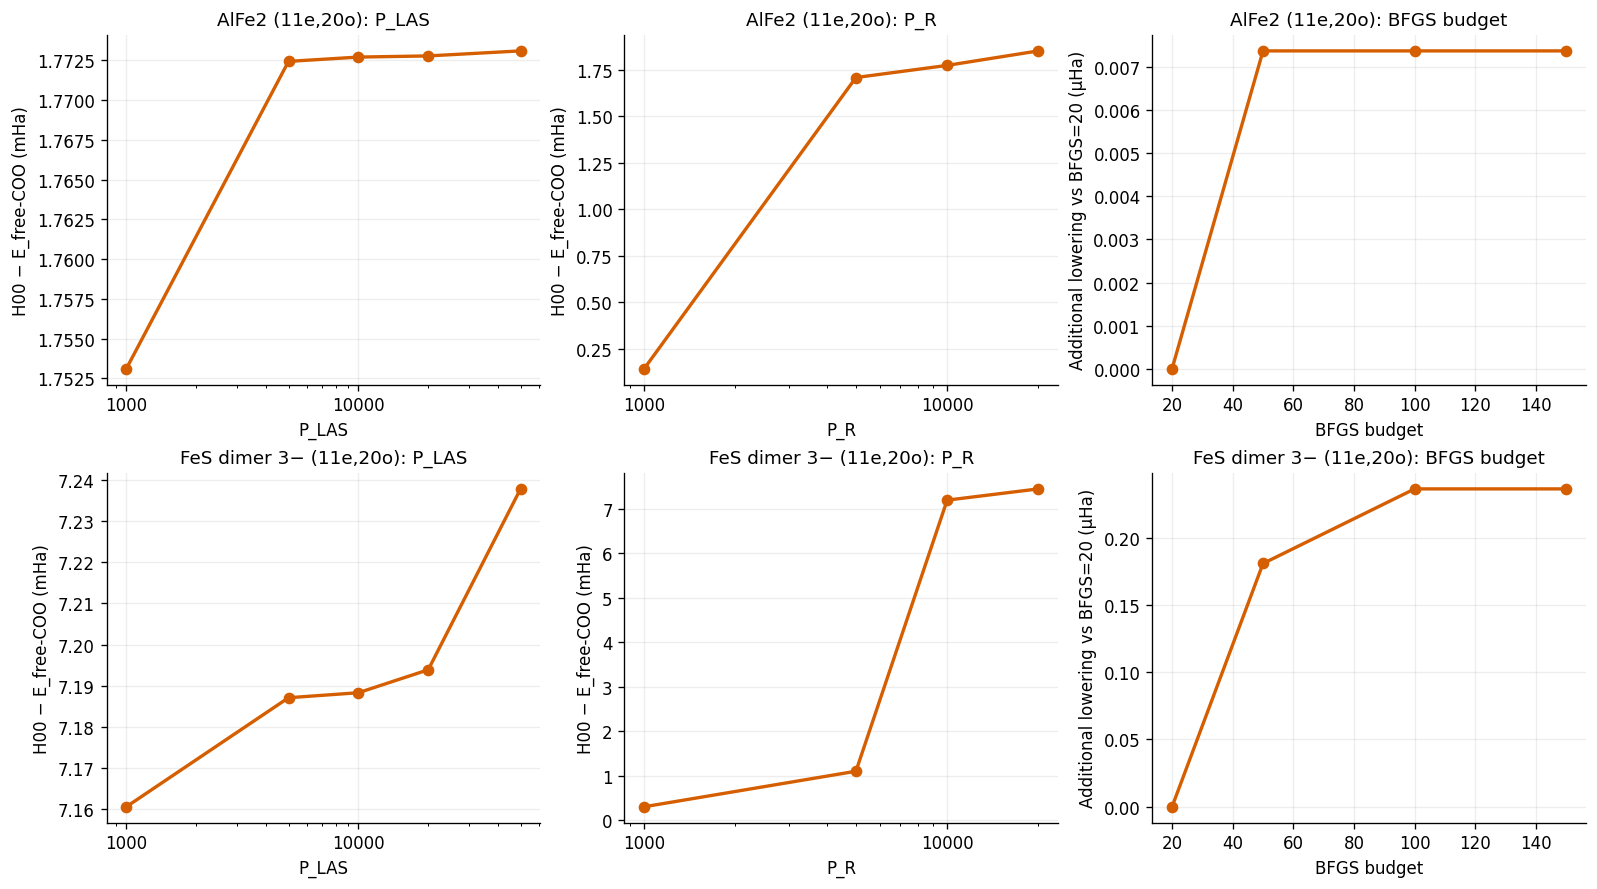

In [2]:
results_path = Path("data/results/03_free_coo_bfgs_sweeps/production_sweep.json")
sweep = json.loads(results_path.read_text())["systems"]
system_order = ["alfe2_11o20e", "fes_dimer_3minus"]
system_labels = ["AlFe2 (11e,20o)", "FeS dimer 3− (11e,20o)"]
families = [
    ("P_LAS=", "las_top_k", "P_LAS"),
    ("P_R=", "recovery_target", "P_R"),
    ("BFGS=", "free_coo_orbital_opt_max_iter", "BFGS budget"),
]

fig, axes = plt.subplots(2, 3, figsize=(13.2, 7.3), constrained_layout=True)
for i, (syskey, syslabel) in enumerate(zip(system_order, system_labels)):
    points = sweep[syskey]["points"]
    for j, (prefix, field, xlabel) in enumerate(families):
        selected = [p for label, p in points.items() if label.startswith(prefix)]
        selected.sort(key=lambda p: p["config"][field])
        x = [p["config"][field] for p in selected]
        y = [1000 * (p["energies_ha"]["h00"] - p["energies_ha"]["free_coo"]) for p in selected]
        if j == 2:
            y = [1000 * (value - y[0]) for value in y]
        axes[i, j].plot(x, y, "o-", color=COLORS["free"], linewidth=2)
        axes[i, j].set_xlabel(xlabel)
        axes[i, j].set_ylabel("Additional lowering vs BFGS=20 (μHa)" if j == 2
                              else "H00 − E_free-COO (mHa)")
        axes[i, j].set_title(f"{syslabel}: {xlabel}")
        if j < 2:
            axes[i, j].set_xscale("log")
            axes[i, j].xaxis.set_major_formatter(ScalarFormatter())
plt.show()

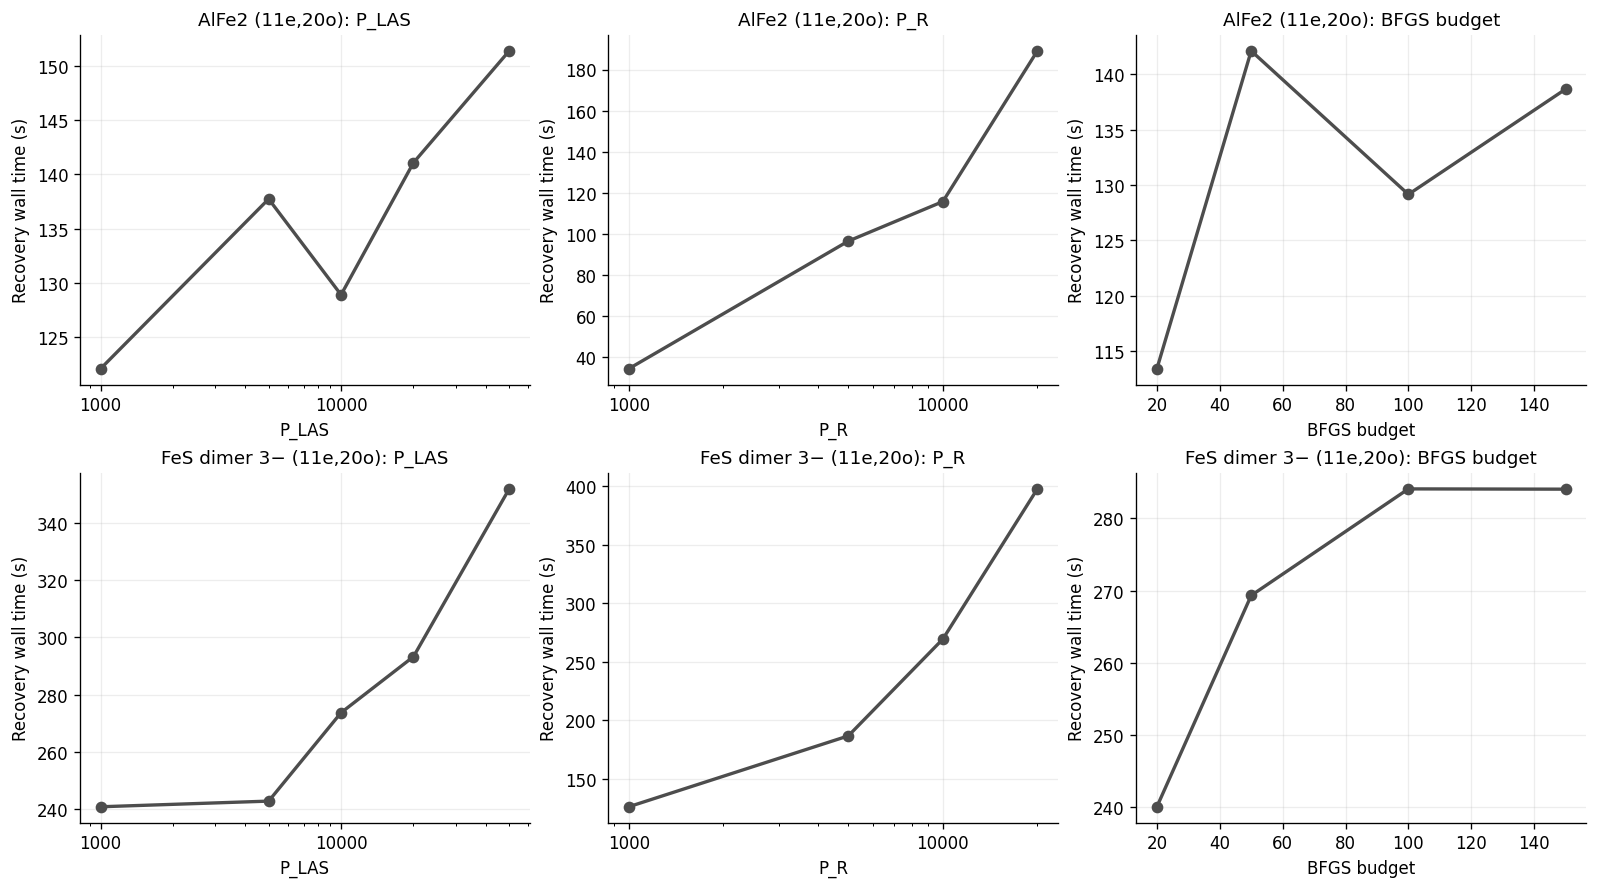

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13.2, 7.3), constrained_layout=True)
for i, (syskey, syslabel) in enumerate(zip(system_order, system_labels)):
    points = sweep[syskey]["points"]
    for j, (prefix, field, xlabel) in enumerate(families):
        selected = [p for label, p in points.items() if label.startswith(prefix)]
        selected.sort(key=lambda p: p["config"][field])
        x = [p["config"][field] for p in selected]
        y = [p["wall_s"] for p in selected]
        axes[i, j].plot(x, y, "o-", color=COLORS["parent"], linewidth=2)
        axes[i, j].set_xlabel(xlabel)
        axes[i, j].set_ylabel("Recovery wall time (s)")
        axes[i, j].set_title(f"{syslabel}: {xlabel}")
        if j < 2:
            axes[i, j].set_xscale("log")
            axes[i, j].xaxis.set_major_formatter(ScalarFormatter())
plt.show()

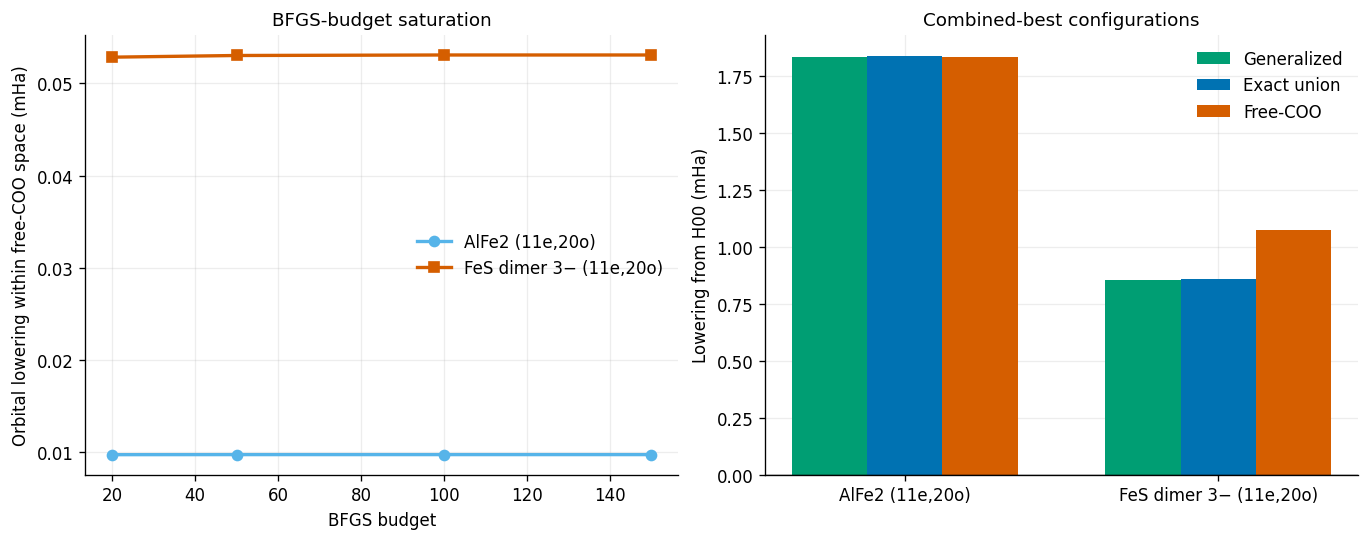

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.3, 4.4), constrained_layout=True)
for syskey, syslabel, marker, color in zip(system_order, system_labels, ["o", "s"],
                                           [COLORS["adapter"], COLORS["free"]]):
    points = sweep[syskey]["points"]
    selected = [p for label, p in points.items() if label.startswith("BFGS=")]
    selected.sort(key=lambda p: p["config"]["free_coo_orbital_opt_max_iter"])
    axes[0].plot([p["config"]["free_coo_orbital_opt_max_iter"] for p in selected],
                 [p["free_coo_gain_mha"] for p in selected], marker=marker,
                 label=syslabel, color=color, linewidth=2)
axes[0].set(xlabel="BFGS budget", ylabel="Orbital lowering within free-COO space (mHa)",
            title="BFGS-budget saturation")
axes[0].legend()

x = np.arange(2); width = 0.24
for j, (label, field, color) in enumerate([
    ("Generalized", "generalized", COLORS["generalized"]),
    ("Exact union", "union", COLORS["union"]),
    ("Free-COO", "free_coo", COLORS["free"]),
]):
    vals = []
    for syskey in system_order:
        p = sweep[syskey]["points"]["combined_best"]
        vals.append(1000 * (p["energies_ha"]["h00"] - p["energies_ha"][field]))
    axes[1].bar(x + (j-1)*width, vals, width, label=label, color=color)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks(x, system_labels)
axes[1].set_ylabel("Lowering from H00 (mHa)")
axes[1].set_title("Combined-best configurations")
axes[1].legend()
plt.show()

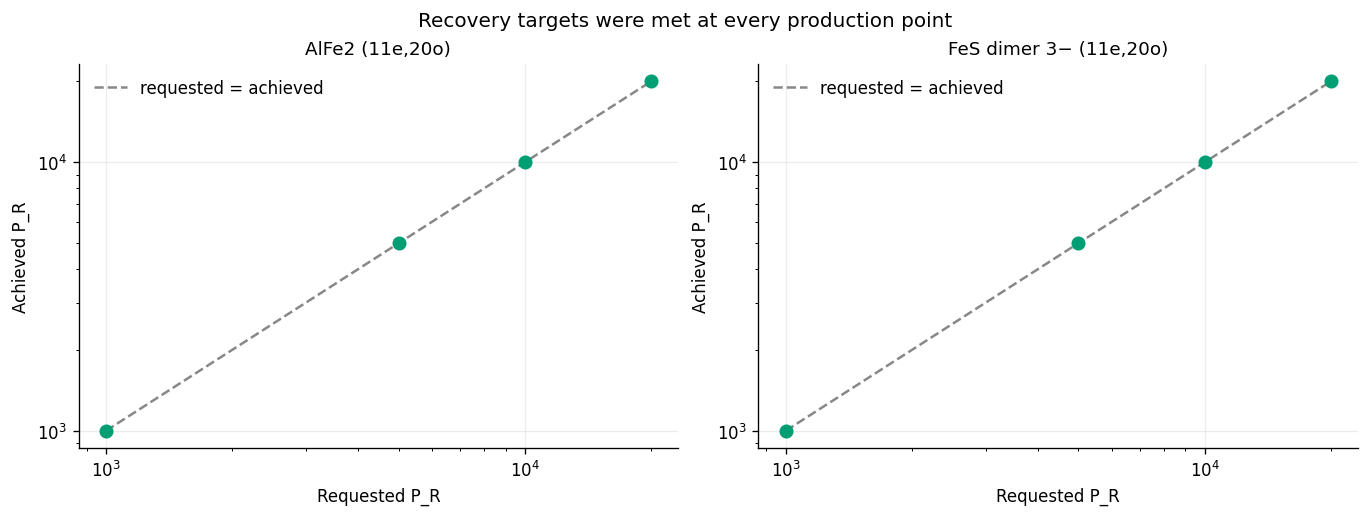

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.3, 4.2), constrained_layout=True)
for ax, syskey, syslabel in zip(axes, system_order, system_labels):
    points = sweep[syskey]["points"]
    selected = [p for label, p in points.items() if label.startswith("P_R=")]
    selected.sort(key=lambda p: p["determinants"]["requested"])
    requested = [p["determinants"]["requested"] for p in selected]
    achieved = [p["determinants"]["achieved"] for p in selected]
    ax.plot(requested, requested, "--", color="#888888", label="requested = achieved")
    ax.scatter(requested, achieved, s=55, color=COLORS["generalized"], zorder=3)
    ax.set(xlabel="Requested P_R", ylabel="Achieved P_R", title=syslabel)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.legend()
fig.suptitle("Recovery targets were met at every production point", fontsize=12)
plt.show()

## Production 2D joint sweep

Real `(P_LAS, P_R)` joint sweeps for both systems at their already-selected BFGS budgets
(`alfe2_11o20e`: 50, `fes_dimer_3minus`: 100 -- reused from the completed one-factor
selection above, not re-screened). Raw data:
`data/results/03_free_coo_bfgs_sweeps/combined_2d_sweep.json` (`production_sweep.json`
and `systems_pilot.json` are untouched). Same conventions as notebook 01: log axes,
marker size = wall time, marker outline = gate/target status.

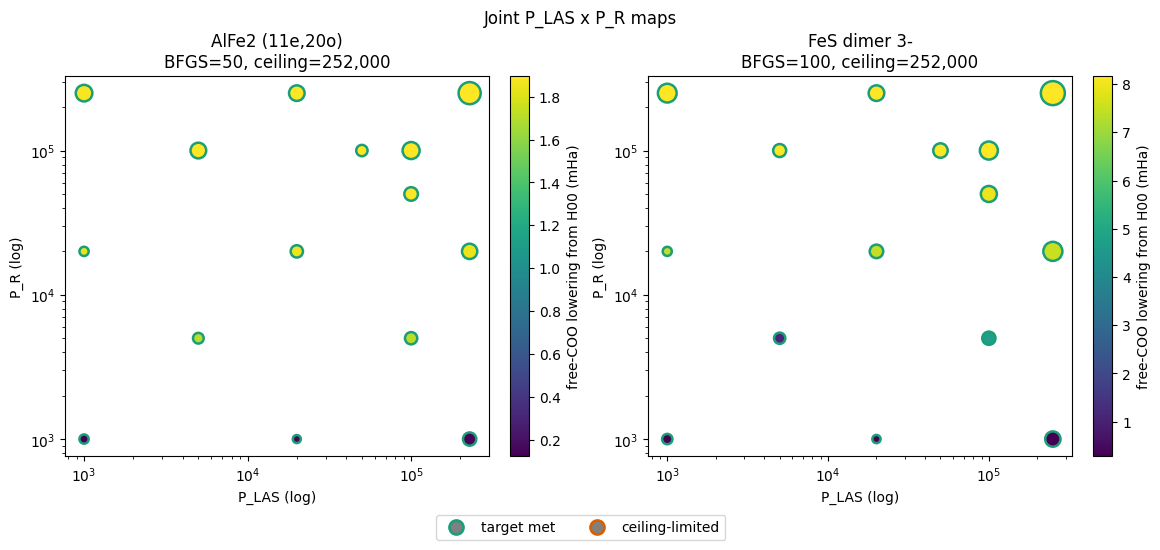

In [1]:

%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

COLORBLIND = {"cmap": "viridis", "ok_edge": "#1B9E77", "ceiling_edge": "#D95F02"}

sweep_b3 = json.loads(Path("data/results/03_free_coo_bfgs_sweeps/combined_2d_sweep.json").read_text())["systems"]
order_b3 = ["alfe2_11o20e", "fes_dimer_3minus"]
labels_b3 = ["AlFe2 (11e,20o)", "FeS dimer 3-"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
for ax, key, label in zip(axes, order_b3, labels_b3):
    entry = sweep_b3[key]
    pts = entry["points"]
    xs, ys, cs, ss, edges = [], [], [], [], []
    for pt in pts.values():
        if pt.get("failed"):
            continue
        d = pt["determinants"]
        xs.append(max(d["P_LAS_actual"], 1))
        ys.append(d["P_R_requested"])
        cs.append(pt["derived_common_baseline_mha"]["free_coo_total_lowering_from_h00_mha"])
        ss.append(20 + 3.0 * np.sqrt(max(pt["wall_s_total"], 0.01)))
        edges.append(COLORBLIND["ok_edge"] if d["P_R_target_met"] else COLORBLIND["ceiling_edge"])
    sc = ax.scatter(xs, ys, c=cs, s=ss, cmap=COLORBLIND["cmap"], edgecolors=edges,
                     linewidths=1.8, zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("P_LAS (log)"); ax.set_ylabel("P_R (log)")
    ax.set_title(f"{label}\nBFGS={entry['bfgs_selected']}, ceiling={entry['las_product_ceiling']:,}")
    fig.colorbar(sc, ax=ax, label="free-COO lowering from H00 (mHa)")

legend_elems = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
           markeredgecolor=COLORBLIND["ok_edge"], markeredgewidth=2, markersize=10,
           label="target met"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
           markeredgecolor=COLORBLIND["ceiling_edge"], markeredgewidth=2, markersize=10,
           label="ceiling-limited"),
]
fig.legend(handles=legend_elems, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Joint P_LAS x P_R maps", y=1.04)
plt.show()


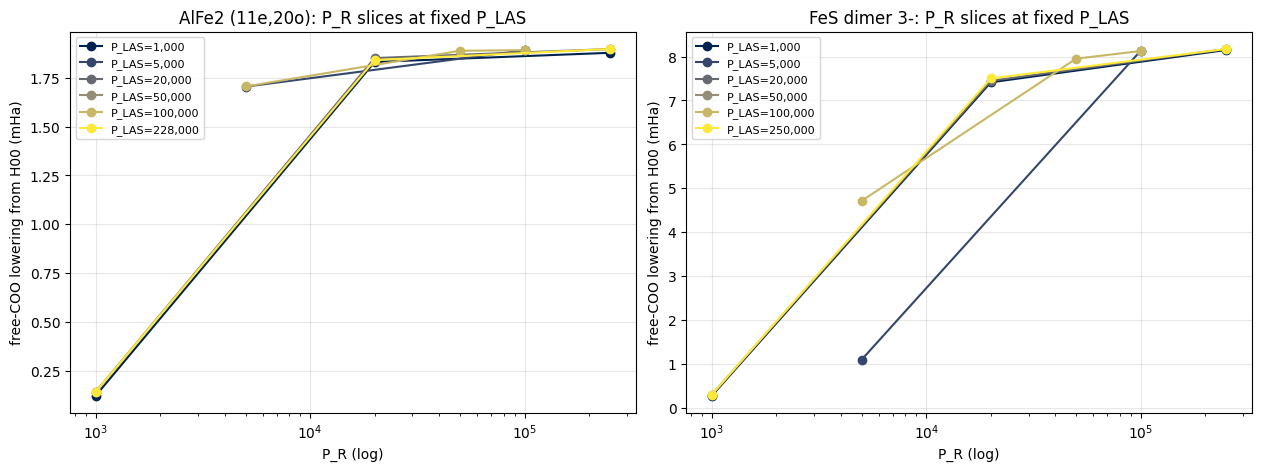

In [2]:

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
for ax, key, label in zip(axes, order_b3, labels_b3):
    entry = sweep_b3[key]
    by_plas = {}
    for pt in entry["points"].values():
        if pt.get("failed"):
            continue
        d = pt["determinants"]
        by_plas.setdefault(d["P_LAS_actual"], []).append(
            (d["P_R_requested"], pt["derived_common_baseline_mha"]["free_coo_total_lowering_from_h00_mha"]))
    cmap = plt.get_cmap("cividis")
    plas_vals = sorted(by_plas)
    for i, plas in enumerate(plas_vals):
        series = sorted(by_plas[plas])
        xs = [s[0] for s in series]; ys = [s[1] for s in series]
        ax.plot(xs, ys, marker="o", color=cmap(i / max(len(plas_vals) - 1, 1)),
                label=f"P_LAS={plas:,}")
    ax.set_xscale("log")
    ax.set_xlabel("P_R (log)"); ax.set_ylabel("free-COO lowering from H00 (mHa)")
    ax.set_title(f"{label}: P_R slices at fixed P_LAS")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.show()


System              P_LAS      P_R  BFGS      Abs energy  H00-lowering(mHa)  Orbital gain(mHa)  union_ndets   wall(s)
alfe2_11o10e            5      835    20    -3971.792709             1.2178             0.0000          840       0.9
bisdiazene          5,184   16,836    50     -295.584992            15.5589             0.8341       22,020     166.6
c2h6n4_paper        1,296    3,136    20     -296.879579             0.0495             0.0000        4,432      17.2
alfe2_11o20e       20,000  250,000    50    -3971.892166             1.8971             0.0000      478,000    1239.6
fes_dimer_3minus  250,000  250,000   100    -5068.755997             8.1720             0.0006      502,000    8650.1


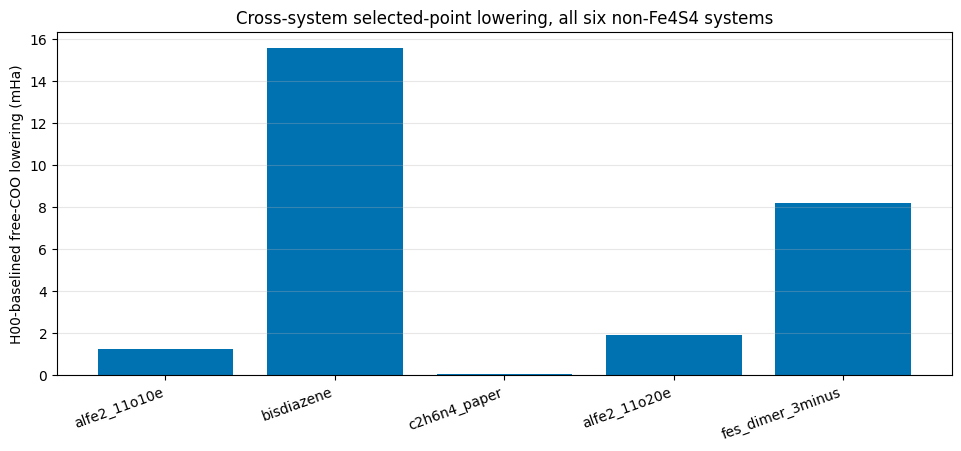

In [3]:

import sys
sys.path.insert(0, "/tmp")

def select_final_point(points):
    valid = [(label, pt) for label, pt in points.items() if not pt.get("failed")]
    valid.sort(key=lambda kv: kv[1]["energies_ha"]["free_coo_after"])
    best_label, best_pt = valid[0]
    best_e = best_pt["energies_ha"]["free_coo_after"]
    ties = [(l, p) for l, p in valid if p["energies_ha"]["free_coo_after"] - best_e < 1e-6]
    ties.sort(key=lambda kv: kv[1]["wall_s_total"])
    return ties[0]

small_b = json.loads(Path("data/results/01_parent_recovery_lassis/combined_2d_sweep.json").read_text())["systems"]

cross_rows = []
for key, entry in list(small_b.items()) + [(k, sweep_b3[k]) for k in order_b3]:
    sel_label, sel_pt = select_final_point(entry["points"])
    base = sel_pt["derived_common_baseline_mha"]
    cross_rows.append(dict(
        system=key, p_las=sel_pt["determinants"]["P_LAS_actual"],
        p_r=sel_pt["determinants"]["P_R_achieved"], bfgs=entry["bfgs_selected"],
        abs_energy=sel_pt["energies_ha"]["free_coo_after"],
        h00_lowering_mha=base["free_coo_total_lowering_from_h00_mha"],
        orbital_lowering_mha=base["free_coo_orbital_gain_mha"],
        union_n_dets=sel_pt["determinants"]["union_n_dets"],
        free_coo_n_dets=sel_pt["determinants"]["free_coo_n_dets"],
        wall_s=sel_pt["wall_s_total"],
    ))

print(f"{'System':<16}{'P_LAS':>9}{'P_R':>9}{'BFGS':>6}{'Abs energy':>16}{'H00-lowering(mHa)':>19}{'Orbital gain(mHa)':>19}{'union_ndets':>13}{'wall(s)':>10}")
for r in cross_rows:
    print(f"{r['system']:<16}{r['p_las']:>9,}{r['p_r']:>9,}{r['bfgs']:>6}{r['abs_energy']:>16.6f}"
          f"{r['h00_lowering_mha']:>19.4f}{r['orbital_lowering_mha']:>19.4f}{r['union_n_dets']:>13,}{r['wall_s']:>10.1f}")

fig, ax = plt.subplots(figsize=(9.5, 4.4), constrained_layout=True)
x = np.arange(len(cross_rows))
ax.bar(x, [r["h00_lowering_mha"] for r in cross_rows], color="#0072B2")
ax.set_xticks(x); ax.set_xticklabels([r["system"] for r in cross_rows], rotation=20, ha="right")
ax.set_ylabel("H00-baselined free-COO lowering (mHa)")
ax.set_title("Cross-system selected-point lowering, all six non-Fe4S4 systems")
ax.grid(axis="y", alpha=0.3)
plt.show()
